# Tetrahedral mesher backends compared

`tetrahedralize` fills a closed triangle surface with tetrahedra, and it reaches several meshers by name: the native **octree** backend (always built), **Netgen**, and the installed **TetGen** and **Gmsh** programs, and the installed **fTetWild** (Hu et al., *Fast Tetrahedral Meshing in the Wild*, 2020), which fits its boundary within an envelope around the skin instead of keeping it. The octree backend also has an opt-in remeshing pass from v20.1.0, `post_adapt=True` (`adapt_volume` run on its tetrahedra), so this notebook compares it twice: plain, and **adapted**. At the same `h` the octree's interior is much finer than the other backends' (about four times Netgen's count on the sphere), so a third octree row, **octree (matched)**, coarsens the same octree call until its tetrahedra count is within 15% of the median of the skin-keeping backends, for a comparison at a comparable element count.

Each backend meshes the same four skins, three primitives and one scanned model (the Stanford bunny), at a target edge `h` per skin. Besides the number of tetrahedra the comparison reports what the mesh is worth: whether the skin is kept, the distance to it, volume error, the dihedral-angle range, sliver counts, and the distributions of the scaled Jacobian and aspect ratio from `compute_quality`. See `doc/tetrahedralize.md` ("Backend comparison") for the tables this notebook produced.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp

try:
    import pyvista as pv
    pv.OFF_SCREEN = True
    pv.set_jupyter_backend('static')
except ImportError:  # pragma: no cover
    pv = None


def gl_available():
    """Probe off-screen GL in a child process: a missing GL stack can kill the
    interpreter outright, which no try/except in this one would survive."""
    if pv is None:
        return False
    import subprocess, sys
    probe = ('import pyvista as pv; pv.OFF_SCREEN = True; pl = pv.Plotter(off_screen=True); '
             'pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)')
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True,
                              timeout=120).returncode == 0
    except Exception:
        return False


GL = gl_available()
print('PyVista rendering' if GL else 'matplotlib fallback (no off-screen GL)')

warnings.simplefilter('ignore', RuntimeWarning)
print('backends:', mp.tetrahedralize_backends(), '| netgen built in:', mp.has_netgen())

matplotlib fallback (no off-screen GL)
backends: ['gmsh', 'netgen', 'octree', 'tetgen'] | netgen built in: True


## The skins

A sphere (curved, no sharp edges), a unit cube (flat faces and 90-degree edges, which a fitted boundary must reproduce), a cylinder (both), and a **complex geometry**: the Stanford bunny scan shipped in `example/data` (112,402 triangles, thin ears, concave folds), remeshed to 3,000 triangles with `remesh` (ACVD clustering) and orientation-repaired with `repair`, since a mesher needs a closed, consistently oriented skin. The cube and cylinder skins are the boundaries of built-in grids (the cylinder's hexahedra split into tetrahedra by `convert_cells`).

In [2]:
import os
BUNNY = os.path.join(os.path.dirname(os.getcwd()), 'data', 'Bunny.stl')
bunny = mp.repair(mp.remesh(mp.read(BUNNY), 1500))
bb = bunny.points.max(axis=0) - bunny.points.min(axis=0)
H = {'sphere': 0.2, 'cube': 0.2, 'cylinder': 0.2, 'bunny': float(bb.max()) / 18}
def enclosed_volume(surface):
    # divergence theorem over the outward triangles
    tri = np.concatenate([c.data for c in surface.cells if c.type == 'triangle'])
    a, b, c = (surface.points[tri[:, i]] for i in range(3))
    return abs(np.einsum('ij,ij->i', a, np.cross(b, c)).sum() / 6.0)


SKINS = {
    'sphere': (mp.icosa_sphere(1.0, 3), 4.0 / 3.0 * np.pi),
    'cube': (mp.extract_skin(mp.box((5, 5, 5), (1, 1, 1), cell_type='tetra')), 1.0),
    'cylinder': (mp.extract_skin(mp.convert_cells(mp.cylinder(0.5, 1.0, nxy=10, nz=5), mode='simplexify')), np.pi * 0.25),
    'bunny': (bunny, enclosed_volume(bunny)),
}
for name, (s, v) in SKINS.items():
    print(f'{name:9s} {sum(len(c.data) for c in s.cells)} triangles, h = {H[name]:.3f}, enclosed volume {v:.4f}')

sphere    1280 triangles, h = 0.200, enclosed volume 4.1888
cube      300 triangles, h = 0.200, enclosed volume 1.0000
cylinder  800 triangles, h = 0.200, enclosed volume 0.7854
bunny     2996 triangles, h = 5.965, enclosed volume 276325.4636


## One function per backend

Every backend returns a mesh of tetrahedra and a report. `octree + adapt` makes the same `octree_mesh` call `tetrahedralize(backend='octree')` makes (uniform skin grading at the skin's own edge length, `max_size = h`, three fitting rounds) and adds `post_adapt=True` with every `adapt_*` keyword at its default, so the two octree rows differ only by the remeshing pass. `octree (matched)` is the plain call with its skin size and largest leaf both scaled by one factor `f`, found by a few secant steps on `log(count)` so the count lands within 15% of the median count of Netgen, TetGen and Gmsh on that skin (the factor is searched once per skin and the timing is the final call's). `ftetwild` is `tetrahedralize(backend='ftetwild', max_size=h)`: fTetWild's ideal edge `h`, its default envelope (1e-3 of the bounding box diagonal) and optimisation schedule. Quality is measured afterwards on the tetrahedra alone with `compute_quality`, identically for every backend.

In [3]:
def tets_of(mesh):
    blocks = [c for c in mesh.cells if c.type == 'tetra']
    return mp.Mesh(mesh.points, [(b.type, b.data) for b in blocks])


def run_tetrahedralize(name):
    def run(skin, h):
        vol, rep = mp.tetrahedralize(skin, backend=name, max_size=h, return_report=True)
        return vol, rep.get('boundary_preserved'), rep.get('hausdorff_to_surface')
    return run


def skin_edge(skin):
    # the mean edge length of the skin, the size tetrahedralize's octree backend meshes at
    tri = np.concatenate([c.data for c in skin.cells if c.type == 'triangle'])
    p = skin.points
    return float(np.linalg.norm(p[tri] - p[np.roll(tri, -1, axis=1)], axis=2).mean())


def run_octree_adapt(skin, h):
    # The same octree_mesh call tetrahedralize(backend='octree') makes (uniform skin
    # grading at the skin's own size, max_size h, 3 fitting rounds), plus post_adapt=True
    # with every adapt_* keyword at its default: the only difference from the plain row.
    s = min(skin_edge(skin), h)
    vol, rep = mp.octree_mesh(skin, output='tet', max_size=max(h, s), min_size=s, surface_size=s,
                              skin_grading='uniform', fit_iterations=3, attach_distance=False,
                              post_adapt=True, return_report=True)
    return vol, False, rep.get('hausdorff_to_skin')


def octree_scaled(skin, h, f):
    # The plain octree call with the skin size and the largest leaf scaled by f.
    s = min(skin_edge(skin), h) * f
    return mp.octree_mesh(skin, output='tet', max_size=max(h * f, s), min_size=s, surface_size=s,
                          skin_grading='uniform', fit_iterations=3, attach_distance=False,
                          return_report=True)


def n_tets(mesh):
    return sum(len(c.data) for c in mesh.cells if c.type == 'tetra')


MATCH_F = {}     # skin name -> the factor found
TARGET = {}      # skin name -> the count it was matched to
KEEPERS = ('netgen', 'tetgen', 'gmsh')


def find_match_factor(skin, h, target, tol=0.15, steps=8):
    # Secant on log(count) against log(f), from the plain call (f = 1) and a first guess
    # from the count's cube law; keeps the best factor seen.
    f0, c0 = 1.0, n_tets(octree_scaled(skin, h, 1.0)[0])
    best = (abs(np.log(c0 / target)), f0, c0)
    f1 = f0 * (c0 / target) ** (1.0 / 3.0)
    for _ in range(steps):
        c1 = n_tets(octree_scaled(skin, h, f1)[0])
        best = min(best, (abs(np.log(c1 / target)), f1, c1))
        if abs(c1 / target - 1.0) <= tol:
            break
        slope = (np.log(c1) - np.log(c0)) / (np.log(f1) - np.log(f0)) if f1 != f0 else -3.0
        slope = min(slope, -0.5)  # the count falls as f grows
        f0, c0, f1 = f1, c1, float(f1 * np.exp((np.log(target) - np.log(c1)) / slope))
        f1 = float(np.clip(f1, 0.25 * f0, 4.0 * f0))
    return best[1], best[2]


def run_octree_matched(name):
    def run(skin, h):
        if name not in MATCH_F:
            MATCH_F[name], _ = find_match_factor(skin, h, TARGET[name])
        vol, rep = octree_scaled(skin, h, MATCH_F[name])
        return vol, False, rep.get('hausdorff_to_skin')
    return run


RUNNERS = {}
for name in mp.tetrahedralize_backends():
    RUNNERS[name] = run_tetrahedralize(name)
RUNNERS['octree + adapt'] = run_octree_adapt
RUNNERS['octree (matched)'] = None  # per skin, once the skin-keeping backends have run
order = [n for n in ('octree', 'octree (matched)', 'octree + adapt', 'netgen', 'tetgen', 'gmsh',
                     'ftetwild') if n in RUNNERS]
print(order)

['octree', 'octree + adapt', 'netgen', 'tetgen', 'gmsh']


In [4]:
def dihedrals_ok(q, key):
    m = q['metrics'][key]
    return m['min'], m['max'], m['mean']


RESULTS = {}   # (skin, backend) -> dict
# The matched octree runs last on each skin: its target is the others' median count.
run_order = [b for b in order if b != 'octree (matched)'] + ['octree (matched)']
for sname, (skin, true_vol) in SKINS.items():
    for bname in run_order:
        runner = RUNNERS[bname]
        if bname == 'octree (matched)':
            kept_counts = [RESULTS[(sname, b)]['tets'] for b in KEEPERS if (sname, b) in RESULTS]
            # Without a skin-keeping backend: the count of regular tetrahedra of edge h.
            TARGET[sname] = (float(np.median(kept_counts)) if kept_counts
                             else true_vol / (H[sname] ** 3 / (6.0 * np.sqrt(2.0))))
            runner = run_octree_matched(sname)
        best, out = None, None
        for _ in range(3):
            t0 = time.perf_counter()
            out = runner(skin, H[sname])
            dt = time.perf_counter() - t0
            best = dt if best is None else min(best, dt)
        vol, kept, hd = out
        tets = tets_of(vol)
        q = mp.compute_quality(tets)
        cell = q['cell_arrays']
        sj = np.concatenate([np.ravel(a) for a in cell['quality:scaled_jacobian']])
        ar = np.concatenate([np.ravel(a) for a in cell['quality:aspect_ratio']])
        dmin = np.concatenate([np.ravel(a) for a in cell['quality:min_dihedral']])
        dmax = np.concatenate([np.ravel(a) for a in cell['quality:max_dihedral']])
        v = np.concatenate([np.ravel(a) for a in cell['quality:volume']])
        RESULTS[(sname, bname)] = dict(
            tets=len(sj), points=len(tets.points), time=best, kept=bool(kept), hausdorff=hd,
            vol_err=100.0 * (v.sum() - true_vol) / true_vol,
            dmin=dmin.min(), dmax=dmax.max(),
            sliver15=int((dmin < 15).sum()), sliver_sj=int((sj < 0.2).sum()),
            sj_min=sj.min(), sj_mean=sj.mean(), ar_max=ar.max(), ar_mean=ar.mean(),
            inverted=q['num_inverted'], degenerate=q['num_degenerate'],
            sj=sj, ar=ar, dmin_all=dmin, dmax_all=dmax, mesh=tets)
print('done', len(RESULTS), 'runs')
for sname in SKINS:
    r = RESULTS[(sname, 'octree (matched)')]
    print(f"{sname:9s} octree (matched): f = {MATCH_F[sname]:.3f}, {r['tets']} tets "
          f"against a target of {TARGET[sname]:.0f} ({100 * (r['tets'] / TARGET[sname] - 1):+.1f}%)")

meshio warning [adapt_volume.cpp:1997] meshio++: adapt_volume: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape
meshio warning [octree_mesh.cpp:378] meshio++: octree_mesh: adapt: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape


meshio warning [adapt_volume.cpp:1997] meshio++: adapt_volume: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape
meshio warning [octree_mesh.cpp:378] meshio++: octree_mesh: adapt: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape


meshio warning [adapt_volume.cpp:1997] meshio++: adapt_volume: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape
meshio warning [octree_mesh.cpp:378] meshio++: octree_mesh: adapt: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape


meshio warning [adapt_volume.cpp:1997] meshio++: adapt_volume: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape
meshio warning [octree_mesh.cpp:378] meshio++: octree_mesh: adapt: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape
meshio warning [adapt_volume.cpp:1997] meshio++: adapt_volume: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape
meshio warning [octree_mesh.cpp:378] meshio++: octree_mesh: adapt: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape
meshio warning [adapt_volume.cpp:1997] meshio++: adapt_volume: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape
meshio warning [octree_mesh.cpp:378] meshio++: octree_mesh: adapt: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape


meshio warning [adapt_volume.cpp:1997] meshio++: adapt_volume: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape
meshio warning [octree_mesh.cpp:378] meshio++: octree_mesh: adapt: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape


meshio warning [adapt_volume.cpp:1997] meshio++: adapt_volume: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape
meshio warning [octree_mesh.cpp:378] meshio++: octree_mesh: adapt: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape


... (31 outputs left out)

meshio warning [smooth.cpp:1246] smooth: the inversion guard rejected 1 node moves; those nodes held still to keep every incident cell correctly oriented


meshio warning [smooth.cpp:1246] smooth: the inversion guard rejected 1 node moves; those nodes held still to keep every incident cell correctly oriented


meshio warning [adapt_volume.cpp:1997] meshio++: adapt_volume: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape
meshio warning [octree_mesh.cpp:378] meshio++: octree_mesh: adapt: dropped cell_data with no correspondence across the edits: octree:level octree_mesh:shape
meshio warning [octree_mesh.cpp:378] meshio++: octree_mesh: the boundary has 0 open and 1 non-manifold edges


done 20 runs


## Results

The tables below are what `doc/tetrahedralize.md` quotes.

In [5]:
cols = [('tets', 'tets', '{:d}'), ('points', 'points', '{:d}'), ('time', 'time s', '{:.3f}'),
        ('kept', 'skin kept', '{}'), ('hausdorff', 'dist. to skin', '{:.4f}'),
        ('vol_err', 'volume err %', '{:+.2f}'),
        ('dmin', 'min dihedral', '{:.1f}'), ('dmax', 'max dihedral', '{:.1f}'),
        ('sliver15', 'dihedral<15', '{:d}'), ('sliver_sj', 'SJ<0.2', '{:d}'),
        ('sj_min', 'SJ min', '{:.3f}'), ('sj_mean', 'SJ mean', '{:.3f}'),
        ('ar_max', 'AR max', '{:.2f}'), ('ar_mean', 'AR mean', '{:.2f}'),
        ('inverted', 'inverted', '{:d}')]


def table(sname):
    head = ['backend'] + [c[1] for c in cols]
    rows = []
    for b in order:
        r = RESULTS[(sname, b)]
        rows.append([b] + [('-' if r[k] is None else f.format(r[k])) for k, _, f in cols])
    return head, rows


for sname in SKINS:
    head, rows = table(sname)
    print(f'### {sname} (h = {H[sname]:.3g})')
    print('| ' + ' | '.join(head) + ' |')
    print('|' + '---|' * len(head))
    for r in rows:
        print('| ' + ' | '.join(r) + ' |')
    print()

### sphere (h = 0.2)
| backend | tets | points | time s | skin kept | dist. to skin | volume err % | min dihedral | max dihedral | dihedral<15 | SJ<0.2 | SJ min | SJ mean | AR max | AR mean | inverted |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| octree | 15480 | 3203 | 0.224 | False | 0.0072 | -1.50 | 31.9 | 121.5 | 0 | 0 | 0.327 | 0.848 | 2.22 | 1.11 | 0 |
| octree + adapt | 13433 | 2940 | 3.190 | False | 0.0076 | -1.60 | 36.7 | 131.4 | 0 | 0 | 0.225 | 0.664 | 2.61 | 1.24 | 0 |
| netgen | 4070 | 1043 | 0.132 | True | 0.0000 | -0.86 | 22.3 | 142.8 | 0 | 0 | 0.217 | 0.611 | 3.05 | 1.29 | 0 |
| tetgen | 8307 | 1655 | 0.091 | True | 0.0000 | -0.86 | 9.0 | 164.6 | 86 | 48 | 0.117 | 0.637 | 5.53 | 1.34 | 0 |
| gmsh | 5193 | 1186 | 0.146 | True | 0.0000 | -0.86 | 13.6 | 155.5 | 10 | 0 | 0.205 | 0.598 | 3.33 | 1.34 | 0 |

### cube (h = 0.2)
| backend | tets | points | time s | skin kept | dist. to skin | volume err % | min dihedral | max dihedral | dihedral<15 | SJ<0.

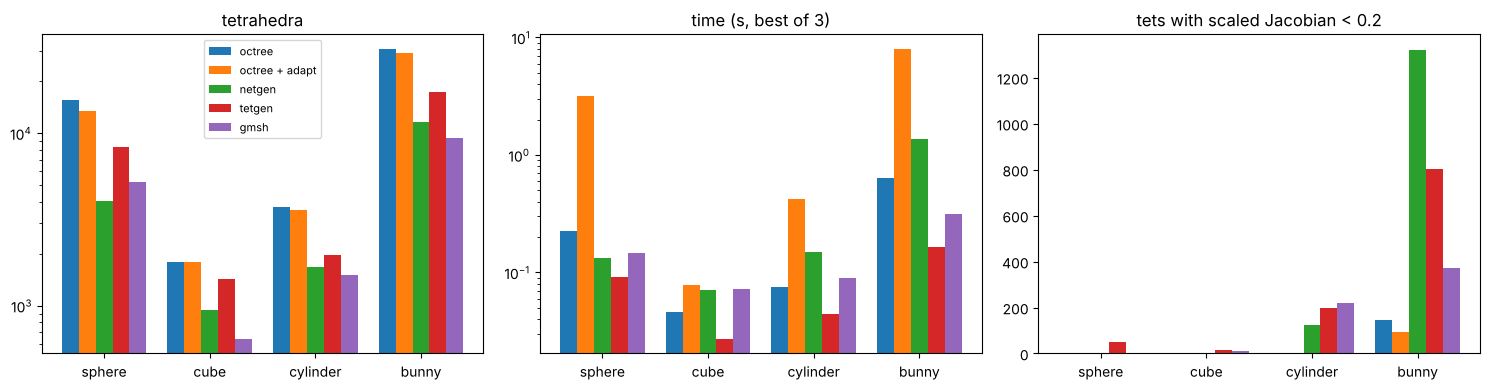

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
w = 0.8 / len(order)
for j, (key, title, log) in enumerate([('tets', 'tetrahedra', True), ('time', 'time (s, best of 3)', True),
                                       ('sliver_sj', 'tets with scaled Jacobian < 0.2', False)]):
    for i, b in enumerate(order):
        vals = [max(RESULTS[(s, b)][key], 1e-3 if log else 0) for s in SKINS]
        ax[j].bar(np.arange(len(SKINS)) + i * w, vals, w, label=b)
    ax[j].set_xticks(np.arange(len(SKINS)) + 0.4 - w / 2)
    ax[j].set_xticklabels(list(SKINS))
    ax[j].set_title(title)
    if log:
        ax[j].set_yscale('log')
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

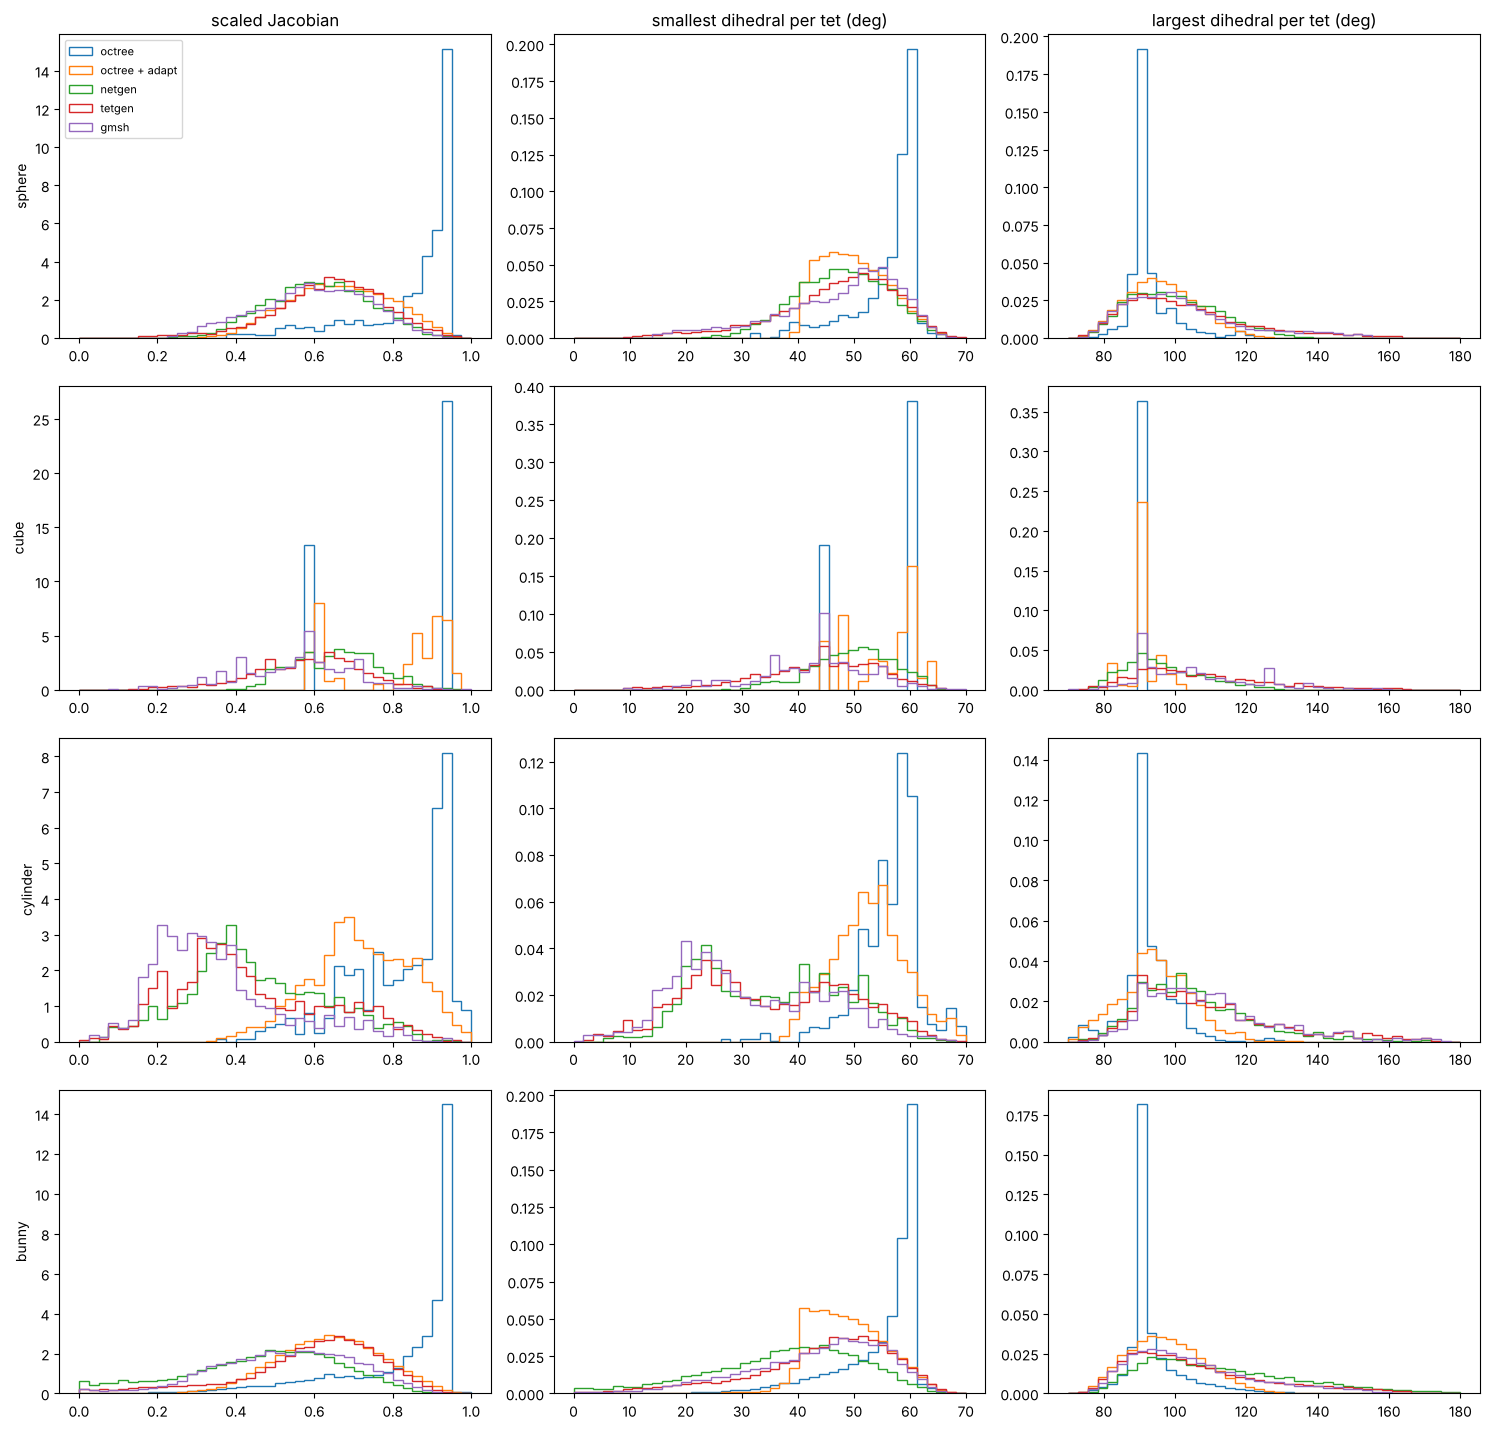

In [7]:
fig, axes = plt.subplots(len(SKINS), 3, figsize=(15, 3.6 * len(SKINS)))
for i, s in enumerate(SKINS):
    for b in order:
        r = RESULTS[(s, b)]
        axes[i][0].hist(r['sj'], bins=40, range=(0, 1), histtype='step', label=b, density=True)
        axes[i][1].hist(r['dmin_all'], bins=40, range=(0, 70), histtype='step', label=b, density=True)
        axes[i][2].hist(r['dmax_all'], bins=40, range=(70, 180), histtype='step', label=b, density=True)
    axes[i][0].set_ylabel(s)
for a, t in zip(axes[0], ['scaled Jacobian', 'smallest dihedral per tet (deg)', 'largest dihedral per tet (deg)']):
    a.set_title(t)
axes[0][0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Cut-away views

The sphere's and the bunny's tetrahedra with the half beyond a plane removed, coloured by scaled Jacobian (red is poor). If GL is unavailable the cell falls back to a matplotlib scatter of the cell centroids on the cut plane.

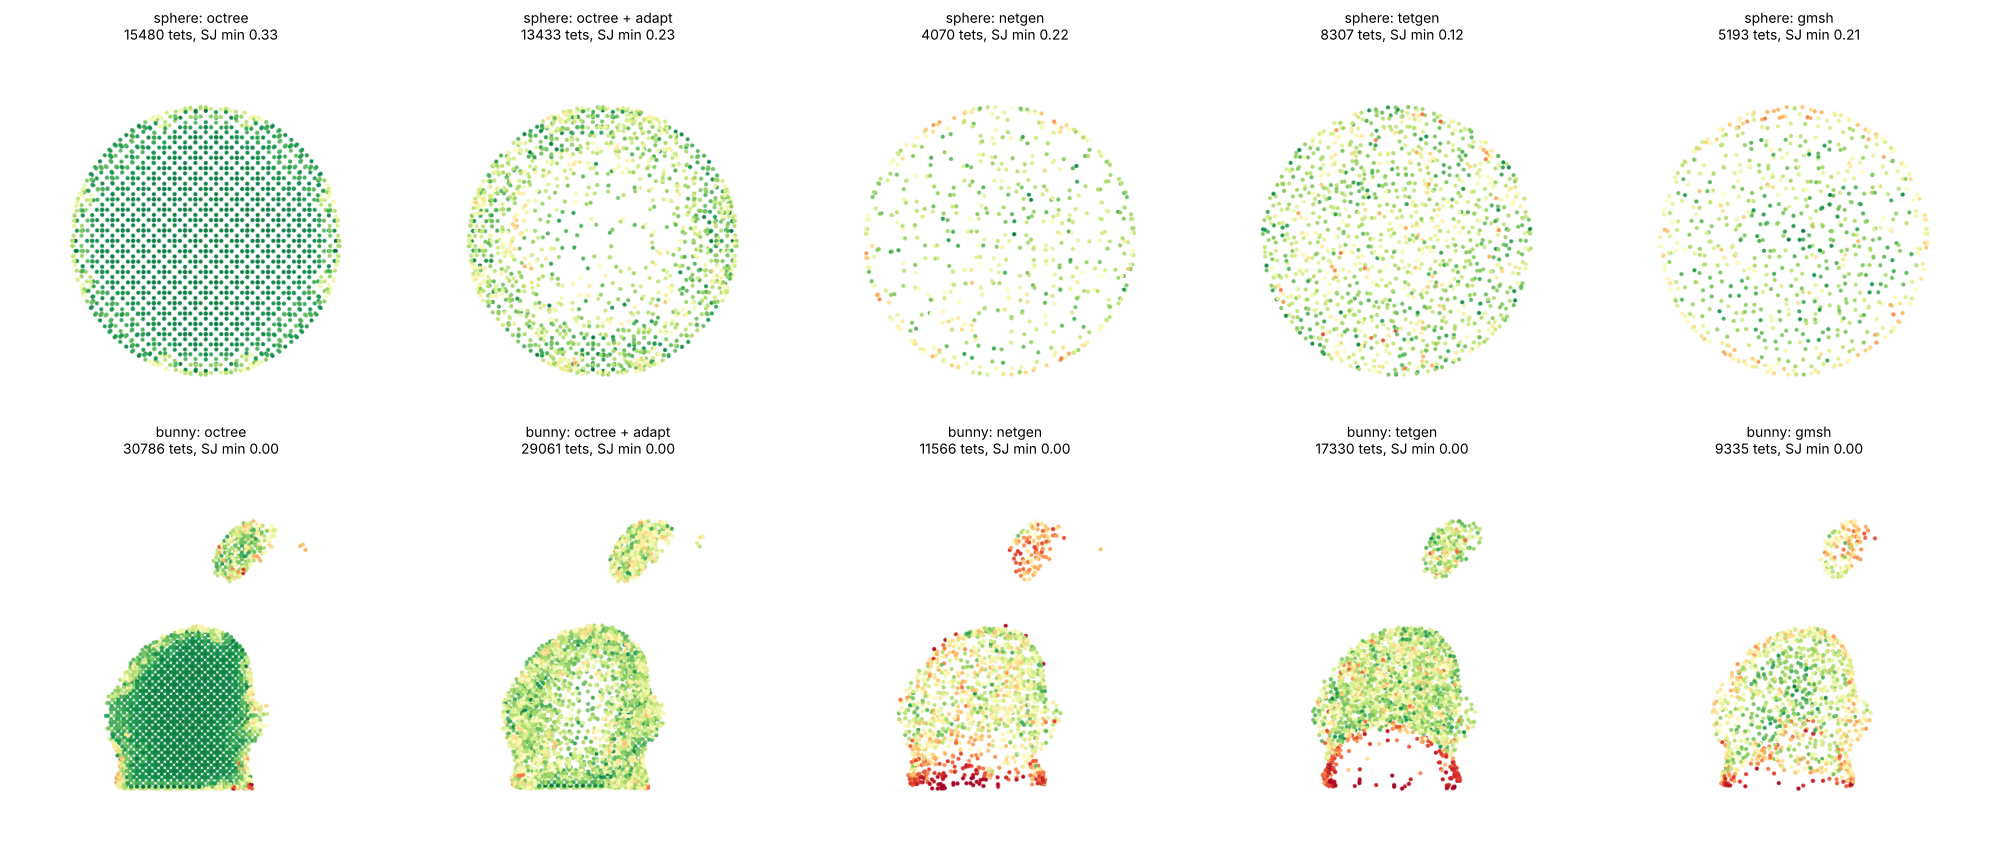

In [8]:
def to_grid(mesh):
    import os, tempfile
    path = os.path.join(tempfile.mkdtemp(), 'v.vtu')
    mp.write(path, mesh)
    return pv.read(path)


def cutaway(mesh, sj):
    cen = mesh.points[mesh.cells[0].data].mean(axis=1)
    mid = 0.5 * (mesh.points[:, 0].min() + mesh.points[:, 0].max())
    keep = cen[:, 0] < mid
    if GL:
        try:
            g = to_grid(mesh)
            g.cell_data['scaled_jacobian'] = sj
            sub = g.extract_cells(np.where(keep)[0])
            pl = pv.Plotter(off_screen=True, window_size=(500, 500))
            pl.add_mesh(sub, scalars='scaled_jacobian', clim=(0, 1), cmap='RdYlGn', show_edges=True,
                        show_scalar_bar=False, line_width=0.3)
            pl.camera_position = 'yz'
            pl.camera.azimuth = 30; pl.camera.elevation = 15
            img = pl.screenshot(return_img=True)
            pl.close()
            return img
        except Exception as exc:  # GL unavailable
            print('PyVista render skipped:', exc)
    sel = keep & (np.abs(cen[:, 0] - cen[keep][:, 0].max()) < 0.1 * np.ptp(cen[:, 0]))
    fig, a = plt.subplots(figsize=(5, 5))
    a.scatter(cen[sel, 1], cen[sel, 2], c=sj[sel], cmap='RdYlGn', vmin=0, vmax=1, s=8)
    a.set_aspect('equal'); a.axis('off')
    fig.canvas.draw()
    img = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
    plt.close(fig)
    return img


fig, axes = plt.subplots(2, len(order), figsize=(4 * len(order), 8.6))
for row, sk in enumerate(('sphere', 'bunny')):
    for a, b in zip(axes[row], order):
        r = RESULTS[(sk, b)]
        a.imshow(cutaway(r['mesh'], r['sj']))
        a.set_title(f"{sk}: {b}\n{r['tets']} tets, SJ min {r['sj_min']:.2f}", fontsize=10)
        a.axis('off')
plt.tight_layout()
plt.show()

## What the adapted octree changes

`post_adapt` is the only difference between the two octree rows: the same stuffed lattice, then `adapt_volume`'s collapse, split, swap and smoothing towards the size field. The ratios below are adapted over plain.

In [9]:
for s in SKINS:
    a, b = RESULTS[(s, 'octree')], RESULTS[(s, 'octree + adapt')]
    print(f"{s:9s} tets x{b['tets'] / a['tets']:.2f}, SJ<0.2 {a['sliver_sj']} -> {b['sliver_sj']}, "
          f"dihedral {a['dmin']:.1f}-{a['dmax']:.1f} -> {b['dmin']:.1f}-{b['dmax']:.1f}, "
          f"SJ mean {a['sj_mean']:.3f} -> {b['sj_mean']:.3f}")

sphere    tets x0.87, SJ<0.2 0 -> 0, dihedral 31.9-121.5 -> 36.7-131.4, SJ mean 0.848 -> 0.664
cube      tets x1.00, SJ<0.2 0 -> 0, dihedral 45.0-90.0 -> 45.0-100.5, SJ mean 0.821 -> 0.804
cylinder  tets x0.96, SJ<0.2 0 -> 0, dihedral 27.1-127.8 -> 38.3-134.9, SJ mean 0.819 -> 0.717
bunny     tets x0.94, SJ<0.2 147 -> 92, dihedral 0.2-179.7 -> 8.6-176.7, SJ mean 0.815 -> 0.636


## The octree at a comparable count

The plain octree's count is set by the skin's own edge length, so at equal `h` it is several times the other backends'. `octree (matched)` scales the same lattice until the count is within 15% of the skin-keeping backends' median: the rows below put the three at about the same number of elements, where the comparison of shape, distance and volume is fair. The ratios are matched over plain.

In [ ]:
cmp = [b for b in ('octree', 'octree (matched)', 'netgen', 'tetgen', 'gmsh', 'ftetwild') if b in order]
print(f"{'skin':9s} {'backend':17s} {'tets':>7s} {'SJ min':>7s} {'SJ mean':>7s} {'dihedral':>13s} "
      f"{'dist.':>8s} {'vol err %':>9s}")
for s in SKINS:
    for b in cmp:
        r = RESULTS[(s, b)]
        hd = '-' if r['hausdorff'] is None else f"{r['hausdorff']:.4f}"
        print(f"{s:9s} {b:17s} {r['tets']:7d} {r['sj_min']:7.3f} {r['sj_mean']:7.3f} "
              f"{r['dmin']:5.1f} - {r['dmax']:5.1f} {hd:>8s} {r['vol_err']:+9.2f}")
    a, m = RESULTS[(s, 'octree')], RESULTS[(s, 'octree (matched)')]
    print(f"{'':9s} matched / plain: tets x{m['tets'] / a['tets']:.2f}, distance x"
          f"{(m['hausdorff'] or 0) / max(a['hausdorff'] or 0, 1e-12):.2f}, f = {MATCH_F[s]:.2f}")
    print()

## Reading the comparison

* **Skin kept or fitted.** Netgen, TetGen and Gmsh keep the input triangles (the core checks it), so neighbouring regions and CAD faces conform; the octree backends and fTetWild fit their own boundary within the reported distance (fTetWild within its envelope, 1e-3 of the bounding box diagonal by default), and the adapted mesh re-measures that distance after remeshing.
* **Matched count.** The `octree (matched)` row is the fair one to set against the skin-keeping backends' element counts: the plain octree spends its extra tetrahedra on a finer interior, not on a better boundary.
* **Count against quality.** The tables put the tetrahedra count beside the angle range, the sliver counts and the scaled Jacobian and aspect-ratio statistics: a backend with fewer elements is not better unless its worst elements are acceptable.
* **Time** is the wall clock of the whole call (best of three; the external programs include writing and reading their files).
* TetGen, Gmsh and fTetWild (`FloatTetwild_bin`, or `MESHIOPLUSPLUS_FTETWILD`) appear only when their programs are installed; Netgen only when the core or the `meshioplusplus-netgen` add-on provides it.